In [1]:
# 基础库
import numpy as np
import xarray as xr
import os
import sys
import gc  
import pickle

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress, t
from arch.bootstrap import MovingBlockBootstrap

# 地理空间处理库
from shapely.geometry import Point
import geopandas as gpd

# 并行处理库
from multiprocessing import Pool, cpu_count

# 可视化库
from matplotlib.ticker import PercentFormatter
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
from cartopy import crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.path as mpath
import matplotlib.ticker as mticker
from matplotlib.colors import Normalize
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import warnings
import matplotlib.patches as mpatches
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None, period_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            if i > trend_select and i < (len_amp - trend_select - min_len):
                continue
            # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            if (j - i - min_len) > trend_select:
                continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    # 计算趋势差 diff
    trend_start = heat_map[1, :trend_select, :trend_select]
    trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]

    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio
    if period_flag:
        return diff, sign, p_diff, trend_start[~np.isnan(trend_start)], trend_end[~np.isnan(trend_end)]
    else:
        return diff, sign, p_diff

def cal_trend_rolling(data, time, min_len):
    """
    计算数据的滚动趋势

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势

    Returns:
    trend_map : 二维数组，包含滚动趋势
    time_map : 二维数组，包含对应的时间映射
    """
    len_amp = len(data)
    # trend_amp [[p, b], rolling]    time_map [start_time, end_time]
    trend_map = np.full((len_amp - min_len, 2), np.nan)
    time_map = np.full((len_amp - min_len, 2), np.nan)

    for i in range(len_amp - min_len):
        amp_now = data[i:i + min_len]
        trend_result = trend_window(amp_now, min_len, cal_type=0, mk_type=1).squeeze()
        trend_map[i] = trend_result
        time_map[i] = [time[i], time[i + min_len]]

    return trend_map, time_map

def p_to_stars(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.05:
        return '**'
    elif p <= 0.1:
        return '*'
    else:
        return ''

def process_trend_diff(args):
    """
    并行处理趋势差异计算的函数。
    """
    data, time, min_line, trend_select = args
    return cal_trend_diff(data, time, min_line, trend_select)

def cal_area_grid(lat, lon, radius=6371000):
    lat_rad = np.radians(lat)
    lat_diff = np.diff(lat_rad) / 2  # 使用中间差值
    
    area = np.zeros((len(lat), len(lon)))
    
    lat_area_factors = radius ** 2 * np.abs(
        np.sin(lat_rad[:-1] + lat_diff) - np.sin(lat_rad[:-1] - lat_diff)
    )

    lon_diff = np.abs(np.radians(lon[1] - lon[0]))

    area[:-1, :] = lat_area_factors[:, np.newaxis] * lon_diff
    area[-1, :] = area[-2, :] 
    area[:, -1] = area[:, -2] 
    
    return area

def cal_MBB_corr_contribusion(x, y, boot_times, block_len, x_num):
    """
    该函数用来使用Moving Block Bootstrapping方法计算序列对于
    例如先有两个序列y1和y2，其中y1 = x1+x2+x3 想要的到针对y1与y2之间相关中，不同变量x的贡献
    输入y为一维数据，x中每一行为不同变量的数据
    一般选择boot_times为1000
    block_len为12
    """
    x = np.transpose(x)
    y = np.transpose(y)
    bs = MovingBlockBootstrap(block_len, x, y = y)
    num = 0

    data_boot = np.zeros((x_num, boot_times))
    # bootstrap计算显著性区间 1 sigma
    for boot in bs.bootstrap(boot_times):
        bs_x = np.squeeze(boot[0][0])
        bs_y = boot[1]['y']

        ## 计算变量和的标准差
        bs_x_sum = np.sum(bs_x, axis=1)
        std_x_sum = np.std(bs_x_sum)

        for num_exp in range(x_num):
            x_temp = bs_x[:, num_exp]
            r = cal_pearson_corr(bs_y, x_temp)
            std_x = np.std(x_temp)

            data_boot[num_exp, num] = r * std_x / std_x_sum
            
        num = num+1

    params = np.full(x_num, np.nan)
    std_sum = np.std(np.sum(x, axis=1))
    for num_exp in range(x_num):
        params[num_exp] = cal_pearson_corr(y, x[:, num_exp]) * np.std(x[:, num_exp]) / std_sum
    param_std = np.std(data_boot, axis=1)
    
    return param_std, params

def cal_pearson_corr(y, x):
    # 确保 x 和 y 是 NumPy 数组
    y = np.array(y)
    x = np.array(x)

    # 去中心化
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    x_diff = x - x_mean
    y_diff = y - y_mean

    # 相关系数公式
    numerator = np.sum(x_diff * y_diff)
    denominator = np.sqrt(np.sum(x_diff**2) * np.sum(y_diff**2))

    r = numerator / denominator
    return r

In [2]:
# Part1 wind与Temperate散点
folder_trendy = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Trendy-GC-amp-Boreal-mask/'
folder_inversion = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Fig-3-GC-exp-amp/'
Part1_dict = {}
st = '1979-12-01'
et = '2021-12-01'
min_len = 20
trend_select = 7
count_diff = np.sum(np.arange(1, trend_select + 1))

files = os.listdir(folder_trendy)
for file in files:
    model = file.split('-')[0]
    ds = xr.open_dataset(folder_trendy + file)
    ds = ds.sel(time=slice('1979-12-01', '2021-12-01'))
    amp_wind = ds.amp_region.values[-1]
    if model not in Part1_dict.keys():
        Part1_dict[model] = {}
    Part1_dict[model]['wind'] = amp_wind
    ds.close()

files = os.listdir(folder_inversion)
for file in files:
    model = file.split('.')[0]
    ds = xr.open_dataset(folder_inversion + file)
    ds = ds.sel(time=slice('1979-12-01', '2021-12-01'))
    amp_wind = ds.amp_region.values[-1]
    if model not in Part1_dict.keys():
        Part1_dict[model] = {}
    Part1_dict[model]['wind'] = amp_wind
    ds.close()

folder_trendy = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Trendy-Temperate-land-amp-cum-region/S3/'
folder_inversion = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Inversion-Temperate-land-amp-cum-region/'

trendy_temp = []
model_list = os.listdir(folder_trendy)
for model in model_list:
    if model == 'VISIT':
        continue
    file = os.path.join(folder_trendy, model, os.listdir(os.path.join(folder_trendy, model))[0])
    ds = xr.open_dataset(file)
    ds = ds.sel(time=slice('1980-12-01', '2022-12-01'))
    amp_cum = ds.amp_cum.values[-1]
    trendy_temp.append(amp_cum)
    Part1_dict[model]['cum'] = amp_cum
    ds.close()
trendy_temp = np.array(trendy_temp).mean(axis=0)
Part1_dict['Trendy']['cum'] = trendy_temp

model_list = os.listdir(folder_inversion)
for model in model_list:
    file = os.path.join(folder_inversion, model, os.listdir(os.path.join(folder_inversion, model))[0])
    ds = xr.open_dataset(file)
    ds = ds.sel(time=slice(str(st), str(et)))
    amp_cum = ds.amp_cum.values
    Part1_dict[model]['cum'] = amp_cum
    ds.close()

cum_temp = []
for key in ['CAMS', 'Jena', 'Trendy']:
    if key == 'Jena':
        idx = 0
    else:
        idx = 2
    cum_temp.append(Part1_dict[key]['cum'][idx:])
    # print(Part1_dict[key]['cum'][idx:].shape)
Part1_dict['Multi-model']['cum'] = np.array(cum_temp).mean(axis=0)

for model, info in Part1_dict.items():
    wind = info['wind']
    cum = info['cum']
    wind_diff, wind_sign, wind_p = cal_trend_diff(wind, np.arange(len(wind)), min_len, trend_select)
    cum_diff, cum_sign, cum_p = cal_trend_diff(cum, np.arange(len(cum)), min_len, trend_select)
    
    info['wind_diff'] = wind_diff
    info['cum_diff'] = cum_diff


In [3]:
# Part2 对Boreal wind的分解
Part2_dict = {}
with open('/public/home/zhujw/work/guoly/code/Paper-2-NH-Transport/Data-pre/GC-output/gc-mask-data.pkl', 'rb') as f:
    model_dict = pickle.load(f)

region_list = ['SH Ocean', 'SH Temperate', 'SH Tropics', 'NH Tropics', 'NH Temperate', 'Boreal']
select_region = region_list[-3:]
exp_list = ['control', 'land', 'ocean', 'fossil', 'wind']
period = 120
lat_line = [-90, -50, -20, 0, 20, 50, 90]
start_year = 1982
end_year = 2022

## 计算不同区域大气传输提供的季节循环
for num_model, (model, info) in enumerate(model_dict.items()):
    smooth_con = info['smooth_cycle_control']
    smooth_data = info['smooth_cycle_exp']
    time_cycle = info['time_cycle']
    
    ## 按照区域off lat_line exp进行排序
    smooth_exp = np.zeros_like(smooth_data)
    for i in range(len(region_list)):
        for j in range(len(region_list)):
            for num_exp in range(len(exp_list)-1):
                if (i == j) and (num_exp == 3):
                    smooth_exp[i, j, num_exp] = smooth_data[i, j, num_exp]
                else:
                    smooth_exp[i, j, num_exp] = smooth_con[j] - smooth_data[i, j, num_exp]
    
    annual_mean = np.mean(smooth_exp[:, :, :, np.where((time_cycle >= start_year) & (time_cycle < end_year))[0]].reshape(len(region_list), len(region_list), len(exp_list)-1, end_year - start_year, period), axis=-2)
    annual_control = np.mean(smooth_con[:, np.where((time_cycle >= start_year) & (time_cycle < end_year))[0]].reshape(len(region_list), end_year - start_year, period), axis=-2)
    info['annual_mean'] = annual_mean
    info['annual_control'] = annual_control

    ## 计算wind source以及import的SC
    wind_annual = np.zeros((len(region_list), len(select_region), period)) # region-off, region, period
    import_annual = np.zeros((len(select_region), period))
    for i in range(len(region_list)):
        for j in range(len(select_region)):
            wind_annual[i, j, :] = annual_mean[i, j+3, -1, :]
    for i in range(len(select_region)):
        import_annual[i, :] = annual_mean[i+3, i+3, -1, :]
    info['wind_annual'] = wind_annual
    info['import_annual'] = import_annual

# wind里面不同分区的贡献
for num_model, (model, info) in enumerate(model_dict.items()):
    
    ## 2、wind里面不同分区的贡献 此处合并南半球三个区域
    wind_sum = np.zeros((len(select_region), period))
    for i in range(len(select_region)):
        wind_sum[i, :] = info['annual_mean'][i+len(select_region), i+len(select_region), -1]
    wind_line_temp = info['annual_mean'][:, -len(select_region):, -1]
    wind_line = np.concatenate((wind_line_temp[:3, :].sum(axis=0)[np.newaxis, :], wind_line_temp[3:, :]), axis=0)

    corr_wind_std, corr_wind = np.zeros((wind_line.shape[1], wind_line.shape[0]-1)), np.zeros((wind_line.shape[1], wind_line.shape[0]-1))
    corr_p, corr_var = np.zeros(len(select_region)), np.zeros(len(select_region))

    for num_area in range(len(select_region)):
        wind_sum_temp = wind_sum[num_area]
        wind_temp = np.delete(wind_line[:, num_area], num_area+1, axis=0) # 此处加1是因为南半球合并
        corr_wind_std[num_area], corr_wind[num_area] = cal_MBB_corr_contribusion(wind_temp, wind_sum_temp, 100, int(period/4), int(wind_temp.shape[0]))
        corr_var[num_area], corr_p[num_area] = pearsonr(np.sum(wind_temp, axis=0), wind_sum_temp)

    info['corr_var'] = corr_var
    info['corr_p'] = corr_p
    info['corr_wind_std'] = corr_wind_std
    info['corr_wind'] = corr_wind
    Part2_dict[model] = info
    
del model_dict


In [4]:
# Part3 计算regional land wind 以及其余变量的趋势差
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/Fig-3-GC-exp-amp/'
part2_dict = {}
lenth_window = 25

for file in files:
    model = file.split('.')[0]
    with xr.open_dataset(folder + file) as ds:
        exp_list_temp = ds['exp_list'].values
        amp_region = ds['amp_region'].values
        time = ds['time'].values
    
    # 合并ocean和fossil的贡献
    if model in ['CAMS', 'Jena']:
        exp_list_temp = np.array(['control', 'land', 'ocean+fossil', 'wind'])
        amp_region_new = np.full((4, amp_region.shape[1]), np.nan)
        amp_region_new[0] = amp_region[0]
        amp_region_new[1] = amp_region[1]
        amp_region_new[2] = amp_region[2] + amp_region[3]
        amp_region_new[3] = amp_region[4]
        amp_region = amp_region_new
    
    if model == 'Multi-model':
        exp_list_temp = np.array(['control', 'land', 'ocean+fossil', 'wind'])
        amp_region_new = np.full((4, amp_region.shape[1]), np.nan)
        amp_region_new[0] = amp_region[0]
        amp_region_new[1] = amp_region[1]
        
          # 读取 CAMS 和 Jena 计算 ocean+fossil 的平均
        with xr.open_dataset(folder + 'CAMS.nc') as ds_cams:
            cams_of = ds_cams['amp_region'].values[2] + ds_cams['amp_region'].values[3]
        with xr.open_dataset(folder + 'Jena.nc') as ds_jena:
            jena_of = ds_jena['amp_region'].values[2] + ds_jena['amp_region'].values[3]
        
        amp_region_new[2] = (cams_of + jena_of) / 2
        amp_region_new[3] = amp_region[-1]
        amp_region = amp_region_new

    nexp = amp_region.shape[0]
    diff_region = np.full((nexp, count_diff), np.nan)
    sign_region = np.full((nexp,), np.nan)
    p_diff_region = np.full((nexp,), np.nan)
    trend_start_region = np.full((nexp, count_diff), np.nan)
    trend_end_region = np.full((nexp, count_diff), np.nan)

    trend_roll = np.full((nexp, amp_region.shape[1] - lenth_window, 2), np.nan)
    time_roll = np.full((nexp, amp_region.shape[1] - lenth_window, 2), np.nan)

    for e in range(amp_region.shape[0]):
        diff, sign, p_diff, trend_start, trend_end = cal_trend_diff(amp_region[e], time, min_len, trend_select, period_flag=True)
        diff_region[e, :] = diff
        sign_region[e] = sign
        p_diff_region[e] = p_diff
        trend_start_region[e, :] = trend_start
        trend_end_region[e, :] = trend_end

        trend_temp, time_temp = cal_trend_rolling(amp_region[e], time, lenth_window)
        trend_roll[e] = trend_temp
        time_roll[e] = time_temp

    part2_dict[model] = {
        'diff_region': diff_region,
        'sign_region': sign_region,
        'p_diff_region': p_diff_region,
        'exp_list': exp_list_temp,
        'trend_roll': trend_roll,
        'time_roll': time_roll,
    }
    print(model, diff_region.shape)
    for e in range(nexp):
        print(f"  Experiment: {exp_list_temp[e]}, "
              f"Sign: {sign_region[e]}, "
              f"P-value: {p_diff_region[e]:.4f}, "
              f"Mean Diff: {np.nanmean(diff_region[e]):.4f}, "
              f"Start: {np.nanmean(trend_start_region[e]/trend_start_region[0])}, "
              f"End: {np.nanmean(trend_end_region[e]/trend_end_region[0])}")
    

Multi-model (4, 28)
  Experiment: control, Sign: 1.0, P-value: 0.0000, Mean Diff: 0.0456, Start: 1.0, End: 1.0
  Experiment: land, Sign: 1.0, P-value: 0.0000, Mean Diff: 0.0226, Start: 0.8605183351625838, End: 0.7166538920545945
  Experiment: ocean+fossil, Sign: 1.0, P-value: 0.0000, Mean Diff: 0.0036, Start: 0.028927216475076626, End: 0.05103051141227918
  Experiment: wind, Sign: 1.0, P-value: 0.0000, Mean Diff: 0.0195, Start: 0.11914208681799442, End: 0.23986315469970793
Trendy (6, 28)
  Experiment: control, Sign: 1.0, P-value: 0.0000, Mean Diff: 0.0507, Start: 1.0, End: 1.0
  Experiment: land, Sign: 1.0, P-value: 0.0000, Mean Diff: 0.0277, Start: 0.9216693414266273, End: 0.7827104082317321
  Experiment: CFE, Sign: 1.0, P-value: 0.0000, Mean Diff: 0.0179, Start: 0.36050413207176685, End: 0.354781025721341
  Experiment: CLIM, Sign: 1.0, P-value: 0.0093, Mean Diff: 0.0079, Start: 0.47261290992164245, End: 0.3584145915581923
  Experiment: LULCC, Sign: 1.0, P-value: 0.0005, Mean Diff: 0.

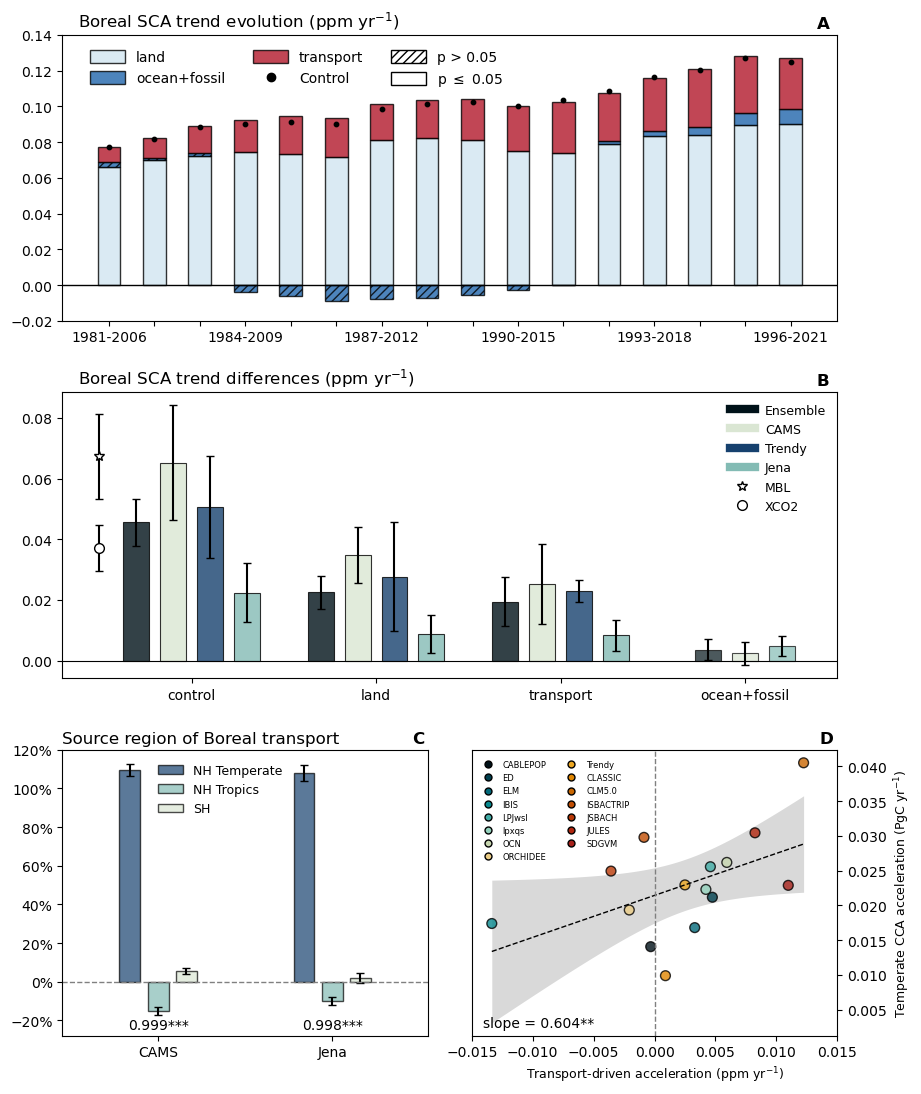

In [ ]:
## 绘图
gs = gridspec.GridSpec(3, 2, width_ratios=[1]*2, height_ratios=[1, 1, 1], wspace=0.12, hspace=0.25)
fig = plt.figure(figsize=(10, 13))  
axs = np.empty((4), dtype=object)
alpha = 0.7
vmax_value = 0.15
labels = ['control', 'land', 'transport', 'ocean+fossil']
exp_list = ['control', 'land', 'transport']  # 只画这三组，ocean+fossil单独画在最后
axs[1] = fig.add_subplot(gs[1, :])
axs[0] = fig.add_subplot(gs[0, :])
axs[2] = fig.add_subplot(gs[2, 0])
axs[3] = fig.add_subplot(gs[2, 1])

# region 1
ax = axs[1]
diff_mean = []
diff_std = []
diff_p = []
models =  ['Ensemble', 'CAMS', 'Trendy', 'Jena']
exp_list = ['control', 'land', 'wind']  # 只画这三组，ocean+fossil单独画在最后 
for num_exp, exp in enumerate(exp_list):  # exp_list: ['control','land','wind']
    for model in models:
        if model == 'Ensemble':
            model_key = 'Multi-model'
        else:
            model_key = model
        info = part2_dict[model_key]
        exp_list_temp = info['exp_list']
        exp_idx = np.where(exp_list_temp == exp)[0][0]
        diff_mean.append(info['diff_region'][exp_idx].mean())
        diff_std.append(info['diff_region'][exp_idx].std())
        diff_p.append(info['p_diff_region'][exp_idx])

# ocean+fossil 只用 CAMS 和 Jena
for model in ['Ensemble', 'CAMS', 'Jena']:
    if model == 'Ensemble':
        model_key = 'Multi-model'
    else:
        model_key = model
    info = part2_dict[model_key]
    diff_mean.append(info['diff_region'][-2].mean())
    diff_std.append(info['diff_region'][-2].std())
    diff_p.append(info['p_diff_region'][-2])

diff_mean = np.array(diff_mean)  # 共 14 个值
diff_std = np.array(diff_std)
diff_p = np.array(diff_p)

# ---- 按 4 组拆分 ----
# 前 12 = 3 组 * 4 模式，最后 3 = ocean+fossil
control_vals = diff_mean[0:4]
land_vals    = diff_mean[4:8]
wind_vals    = diff_mean[8:12]
of_vals      = diff_mean[12:]   # ocean+fossil（3 个）


# ---- 组配置 ----
n_model = 4
n_of    = 3
group_x = np.arange(4)  # [0,1,2,3]

# 每组内“逻辑位置”之间的间距（不是真正的 bar 宽度）
inner_step = 0.2          # 组内相邻bar中心间隔
inner_gap_ratio = 0.3     # 组内bar宽度与step的比例，0.2表示留20%空白
bar_width = inner_step * (1 - inner_gap_ratio)

# 4 根柱子的相对中心位置（以组中心为0）
offsets_4 = (np.arange(n_model) - (n_model - 1) / 2) * inner_step
# 2 根柱子的相对中心位置
offsets_2 = (np.arange(n_of) - (n_of - 1) / 2) * inner_step

colors = ['#001219', '#dae6d3', '#16416e', '#83bbb4']
labels_model = models  

# ----- 画前三组：control / land / wind -----
for i in range(n_model):
    vals_i = [control_vals[i], land_vals[i], wind_vals[i]]
    x_i = group_x[0:3] + offsets_4[i]
    ax.bar(
        x_i, vals_i,
        width=bar_width,
        color=colors[i],
        edgecolor='black',
        yerr=diff_std[i::n_model][0:3],
        capsize=3,
        linewidth=0.8,
        alpha=0.8,
        label=labels_model[i] if i == 0 else None
    )

# ----- 画 ocean+fossil 组 -----
x_last = group_x[3] + offsets_2
ax.bar(
    x_last, of_vals,
    width=bar_width,
    color=[colors[0], colors[1], colors[3]],
    yerr=diff_std[12:],
    edgecolor='black',
    capsize=3,
    linewidth=0.8,
    alpha=0.7
)

# ----- 在control试验添加MBL XCO2对比 -----
ax.set_xlim(-0.7, 3.5)
data = [0.0673, 0.0371]
std = [0.0140, 0.0075]
x_pos = group_x[0] + offsets_4[0] - 0.2  # 在control组的第一个柱子左边
ax.errorbar(x_pos, data[0], yerr=std[0], fmt='*', color='black', 
            markerfacecolor='white', markeredgecolor='black', 
            markersize=7, capsize=3, label='MBL', zorder=3)
ax.errorbar(x_pos, data[1], yerr=std[1], fmt='o', color='black', 
            markerfacecolor='white', markeredgecolor='black', 
            markersize=7, capsize=3, label='XCO2', zorder=3)

ax.set_xticks(group_x)
ax.set_xticklabels(labels, fontsize=10)
ax.tick_params(axis='y', labelsize=10)

custom_lines = [Line2D([0], [0], color=colors[i], lw=6) for i in range(n_model)]
custom_lines.append(Line2D([0], [0], markerfacecolor='white', markeredgecolor='black', marker='*', markersize=7, linestyle='None', label='MBL'))
custom_lines.append(Line2D([0], [0], markerfacecolor='white', markeredgecolor='black', marker='o', markersize=7, linestyle='None', label='XCO2'))
labels_model.append('MBL')
labels_model.append('XCO2')
ax.legend(custom_lines, labels_model,
          fontsize=9, loc='upper right', frameon=False)
ax.text(0.02, 1.01, 'Boreal SCA trend differences (ppm yr$^{-1}$)', fontsize=12,
        va='bottom', ha='left', transform=ax.transAxes)
ax.axhline(0, color='k', linewidth=0.8)
# endregion

# region 2
ax = axs[0]
info = part2_dict['Multi-model']
exp_list = info['exp_list']
trend_roll = info['trend_roll']
time_roll = info['time_roll'][0]
x_data = time_roll[:, 1]
n_points = len(x_data)

# 分别记录正负值的堆叠底线
bottom_pos = np.zeros(n_points)
bottom_neg = np.zeros(n_points)

colors = ['#d1e5f0', '#2166ac', '#b2182b', '#ef8a62']

for n_e, exp in enumerate(exp_list[1:]):
    y_data = trend_roll[n_e+1, :, 1]
    p_data = trend_roll[n_e+1, :, 0] 
    
    # 根据 y 值的正负选择对应的底线
    bottom = np.where(y_data > 0, bottom_pos, bottom_neg)
    
    bars = ax.bar(x_data, y_data, bottom=bottom, label=exp, 
                  color=colors[n_e % len(colors)], width=0.5,
                  edgecolor='black', linewidth=1, alpha=0.8)

    for idx, rect in enumerate(bars):
        if p_data[idx] > 0.1:
            rect.set_hatch('////')

    # 更新底线
    bottom_pos += np.maximum(y_data, 0)
    bottom_neg += np.minimum(y_data, 0)
ax.scatter(x_data, trend_roll[0, :, 1], color='black', s=10, zorder=5)  # 添加散点以突出显示 x 轴
ax.axhline(0, color='black', linewidth=1)

custom_lines = [
    mpatches.Patch(facecolor=colors[i], edgecolor='black', linewidth=1, alpha=0.8) 
    for i in range(len(exp_list)-1)
]
custom_lines.append(Line2D([0], [0], marker='o', color='black', markerfacecolor='black', markersize=6, lw=0, label='Control'))
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', hatch='////', linewidth=1))
custom_lines.append(mpatches.Patch(facecolor='white', edgecolor='black', linewidth=1))
labels_legend = ['land', 'ocean+fossil', 'transport', 'Control', 'p > 0.05', 'p $\leq$ 0.05']
ax.legend(custom_lines, labels_legend, bbox_to_anchor=(0.02, 0.99), 
          loc='upper left', frameon=False, fontsize=10,
          handlelength=2.5, handleheight=1., ncols=3)
ax.text(0.02, 1.01, 'Boreal SCA trend evolution (ppm yr$^{-1}$)', fontsize=12,
        va='bottom', ha='left', transform=ax.transAxes)
xticks_label = []
for i in range(n_points):
    start_year = int(time_roll[i, 0])
    end_year = int(time_roll[i, 1])
    xticks_label.append(f'{start_year}-{end_year}')
ax.set_ylim(-0.02, 0.14)

ax.set_xticks(x_data)  
display_labels = [label if i % 3 == 0 else "" for i, label in enumerate(xticks_label)]
ax.set_xticklabels(display_labels, rotation=0, fontsize=20)
# endregion

# region 3
ax = axs[2]
color_list_wind = np.array(['#16416e', '#83bbb4', '#dae6d3'])
labels = ['NH Temperate', 'NH Tropics', 'SH']
data_value, data_std = [], []
for model, info in Part2_dict.items():
    corr_wind, corr_wind_std = info['corr_wind'], info['corr_wind_std']
    data_value.append(corr_wind[-1][::-1])
    data_std.append(corr_wind_std[-1][::-1])

data_value = np.array(data_value)*100
data_std = np.array(data_std)*100
x_group = ['CAMS', 'Jena']

vals_grp = data_value.reshape(2, 3)  # (2组, 3类)
errs_grp = data_std.reshape(2, 3)

group_gap = 1.5  # >1 会增加组间距（可调：1.2~1.8）
x = np.arange(len(x_group)) * group_gap

bar_w = 0.18          # 柱子更窄一点
inner_gap = 1.35      # 组内“间距系数”，越大同组越松（可调：1.1~1.8）
offsets = (np.arange(3) - 1) * bar_w * inner_gap 

for k in range(3):
    ax.bar(
        x + offsets[k],
        vals_grp[:, k],
        yerr=errs_grp[:, k],
        width=bar_w,
        color=color_list_wind[k],
        edgecolor='black',
        capsize=3,
        alpha=0.7,
        label=labels[k]
    )

ax.set_xticks(x)
ax.set_xticklabels(x_group)
ax.axhline(0, color='grey', linewidth=1, linestyle='--')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
pad = 0.55 * group_gap
ax.set_xlim(x[0] - pad, x[-1] + pad)
ax.legend(frameon=False, fontsize=9, bbox_to_anchor=(0.23, 0.99), loc='upper left')
ax.text(x[0], -19, '0.999***', ha='center',  
        va='top', fontsize=10, color='black')
ax.text(x[1], -19, '0.998***', ha='center',  
        va='top', fontsize=10, color='black')
ax.set_ylim(-28, 120)
ax.text(0.0, 1.04, 'Source region of Boreal transport',
        transform=ax.transAxes, fontsize=12, va='center',
        ha='left')
# endregion

# region 4
ax = axs[3]
ax.yaxis.tick_right()
ax.yaxis.set_label_position("right")

x_all = np.array(
    [np.nanmean(Part1_dict[m]['cum_diff'], axis=0)
    for m in Part1_dict.keys()],
    dtype=float
)
y_all = np.array(
    [np.nanmean(Part1_dict[m]['wind_diff'], axis=0)
    for m in Part1_dict.keys()],
    dtype=float
)
x_all = x_all[:-3]
y_all = y_all[:-3]
# y_all[-1] += 0.005
# x_all[-1] -= 0.003
labels = [list(Part1_dict.keys())[:-3]]
res = linregress(x_all, y_all)
slope, intercept = res.slope, res.intercept
r, p = res.rvalue, res.pvalue

# 回归线 + 95% 置信带（均值置信区间）
x_line = np.linspace(x_all.min(), x_all.max(), 200)
y_line = slope * x_line + intercept

# 标准误与 t 临界值
n = np.isfinite(x_all).sum()
x_mean = np.nanmean(x_all)
Sxx = np.nansum((x_all - x_mean) ** 2)

# 残差标准差 s（注意自由度 n-2）
y_hat = slope * x_all + intercept
resid = y_all - y_hat
s = np.sqrt(np.nansum(resid**2) / (n - 2))

alpha = 0.05
tval = t.ppf(1 - alpha/2, df=n - 2)

se_mean = s * np.sqrt(1/n + (x_line - x_mean)**2 / Sxx)
y_lower = y_line - tval * se_mean
y_upper = y_line + tval * se_mean

# 画置信带阴影 + 回归线
ax.fill_between(x_line, y_lower, y_upper, color='black', alpha=0.15, linewidth=0, zorder=1)
ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=1, zorder=2)

color_map = ['#001219', '#005f73', '#0a9396', '#94d2bd', '#e9d8a6',
             '#ee9b00', '#ca6702', '#bb3e03', '#ae2012', '#9b2226']

n_colors = len(x_all)
cm_custom = LinearSegmentedColormap.from_list('custom', color_map)
color_list = [cm_custom(i / n_colors) for i in range(n_colors)]
ax.scatter(x_all, y_all, s=50, label=model, color=color_list, edgecolors='black', alpha=0.8)

# 在图内标注 R² 和 p（位置可按需调整）
ax.text(
    0.03, 0.02,
    f'slope = {slope:.3g}**',
    transform=ax.transAxes,
    fontsize=10,
    va='bottom'
)

ax.axvline(0, color='gray', linestyle='--', linewidth=1)
# ax.set_title(f'{exp_list[i*2+j]}', fontsize=12)
ax.set_xlim(-0.015, 0.015)
custom_legend = [
    Line2D([0], [0], marker='o', color='w', label=labels[0][i],
           markerfacecolor=color_list[i], markersize=5, markeredgecolor='black')
    for i in range(len(labels[0]))
]
ax.legend(handles=custom_legend, fontsize=6,
          ncols=2, loc='upper left', frameon=False, bbox_to_anchor=(0, 0.99))

ax.text(1.15, 0.5, 'Temperate CCA acceleration (PgC yr$^{-1}$)', 
        rotation=90, va='center', ha='left', fontsize=9, transform=ax.transAxes)
ax.text(0.5, -0.1, 'Transport-driven acceleration (ppm yr$^{-1}$)', 
        rotation=0, va='top', ha='center', fontsize=9, transform=ax.transAxes)
# endregion

letters = list('ABCDEF')
for i, ax in enumerate(axs.flat):
    ax.text(0.99, 1.04, f'{letters[i]}', transform=ax.transAxes, 
            ha='right', va='center', fontsize=12, fontweight='bold')
    ax.tick_params(axis='both', which='major', labelsize=10)
fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/main-text-fig/Fig3.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)